# Circular task analysis
This notebook runs the four notebooks of the project in order.

## 1 - Reading the data (notebooks/01_reading.ipynb)
MouseReMoCo gives two files with the same header line (the parameters of the task):
- 001MoDe_R1.csv: timestamp (ms), mouse position (x, y in pixels) and mouseInTarget (1 = inside the target, 0 = outside);
- 001MoDe_R1.marker.csv: the events of the session (start and end of each record) and the table of results computed by MouseReMoCo.

Main parameters: screen of 1104 × 661 px, center of the circle at (552, 330), internal and external radius of 170 and 250 px,
cursor radius of 16 px, task radius of 209.5 px and task tolerance of 47 px.

Steps:
- read the header and the markers;
- load the data and remove the 5 rows "0,0,0,0" written by MouseReMoCo at the end of each record (19588 samples left);
- express the time in seconds, with t = 0 at the first data point;
- split the session into records with the start (DoRecord) and end (DoPause) markers.

6 records were planned, but the window was closed during the 5th pause: only 5 records of about 20 s are usable
(3971, 3898, 3898, 3884 and 3936 samples, about 198 to 200 Hz).

In [1]:
%run notebooks/01_reading.ipynb

Header line information in 'data/001MoDe_R1.csv':
  screenWidth: 1104.0
  screenHeight: 661.0
  cornerX: 302.0
  cornerY: 80.0
  centerX: 552.0
  centerY: 330.0
  externalRadius: 250.0
  internalRadius: 170.0
  borderRadius: 1.0
  cursorRadius: 16.0
  indexOfDifficulty: 28.00696429476858
  taskRadius: 209.5
  taskTolerance: 47.0
  borderColor: java.awt.Color[r=255,g=255,b=255]
  backgroundColor: java.awt.Color[r=0,g=0,b=0]
  cursorColorRecord: java.awt.Color[r=255,g=0,b=0]
  cursorColorWait: java.awt.Color[r=255,g=255,b=0]
  autoStart: 3600.0
  cycleMaxNumber: 6.0
  cycleDuration: 20.0
  software: LSL-mouse
  version: 1.2.0rc5
  task: CircularTarget
  isWithLSL: false
Same header in both files: True
Markers in 'data/001MoDe_R1.marker.csv':
1616776712325: KeyTyped=32 DoCycleChange
1616776712331: DoCycleChange:DoStartCycleTimedSequence
1616776712333: DoCycleChange:DoRecord RecordDone=0 PauseDone=0 ToDo=6
1616776732336: DoCycleChange:DoPause RecordDone=1 PauseDone=0 ToDo=6
1616776752340: 

## 2 - Graphics (notebooks/02_graphics.ipynb)
The coordinates are centered on the circle (center = (0, 0)) and the y axis points up (on the screen, y points down).
The cursor center is inside the target when its distance to the center is between 186 px (170 + 16) and 233 px (250 - 16 - 1).

- Figure 1: x and y over the whole session, with the start (black) and end (red) of each record.
- Figure 2: trajectory of the whole session, with the limits of the target.
- Figures 3 to 7: trajectory of each record, points inside (green) and outside (red) the target, with the screen (magenta) and the target ring (yellow).
- Figure 8: distance to the center (r) of each record over time, with the limits of the target.
- Figures 9 to 13: x, y and mouseInTarget of each record over time.

Main observations: in records 1 to 4, the cursor starts outside the target, on the right, and enters it in less than 1 s.
Record 0 starts directly inside the target. Once inside, the cursor mostly stays in the ring: the red points are at its edges.

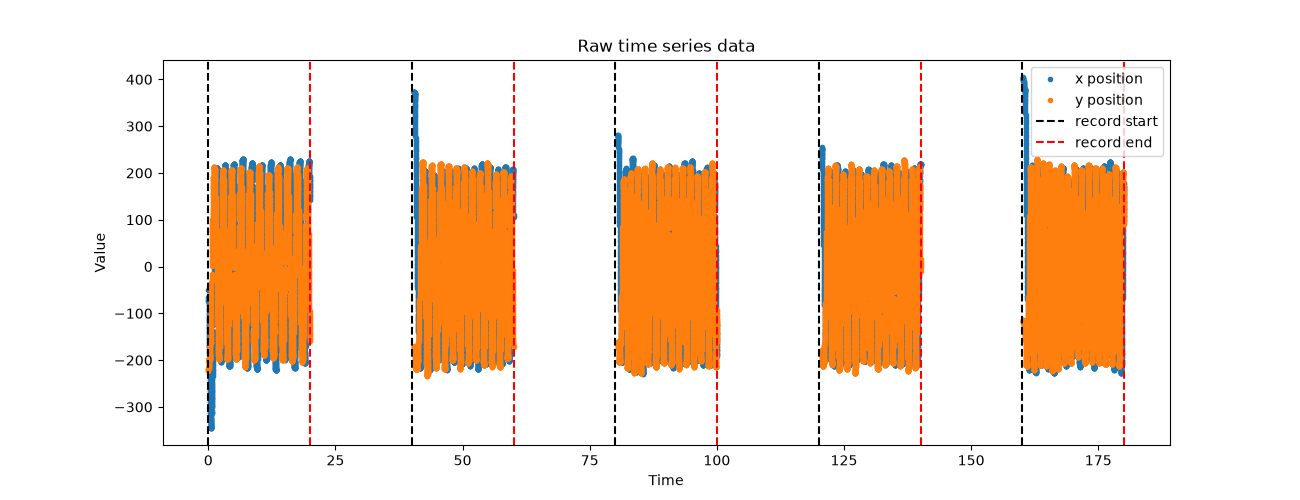

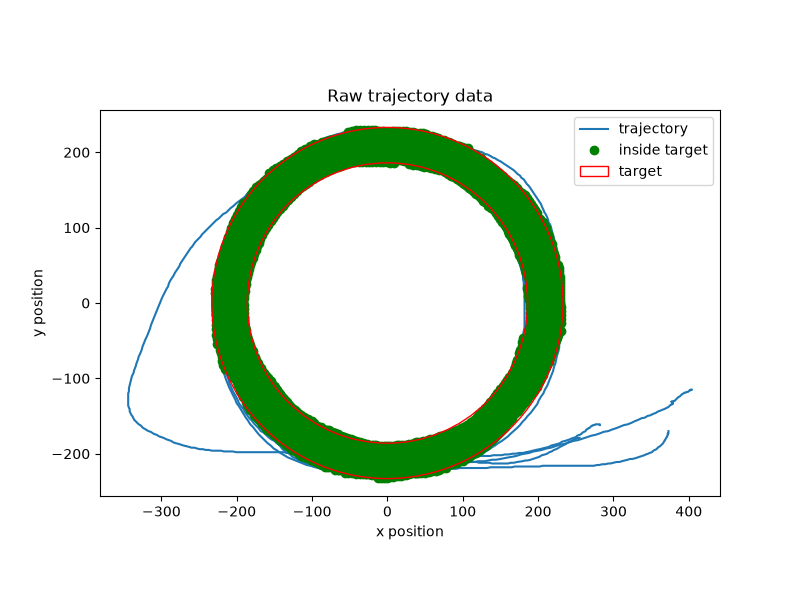

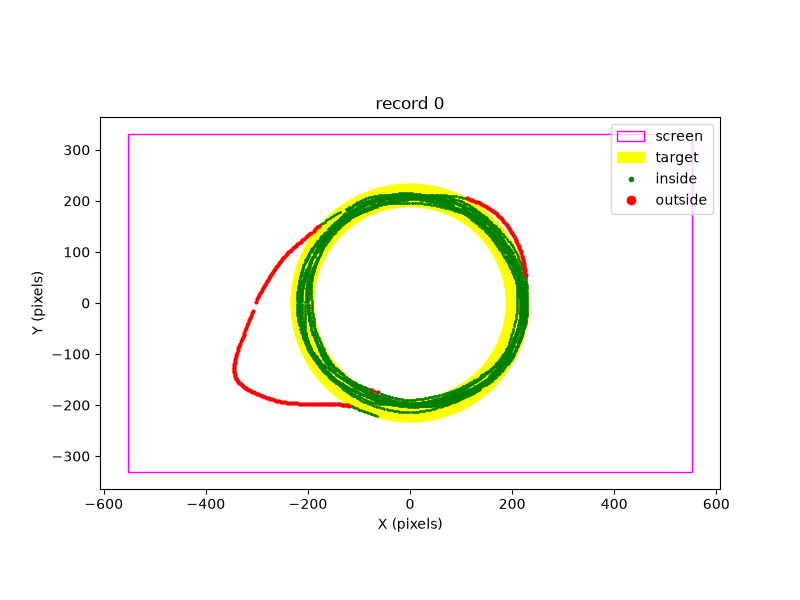

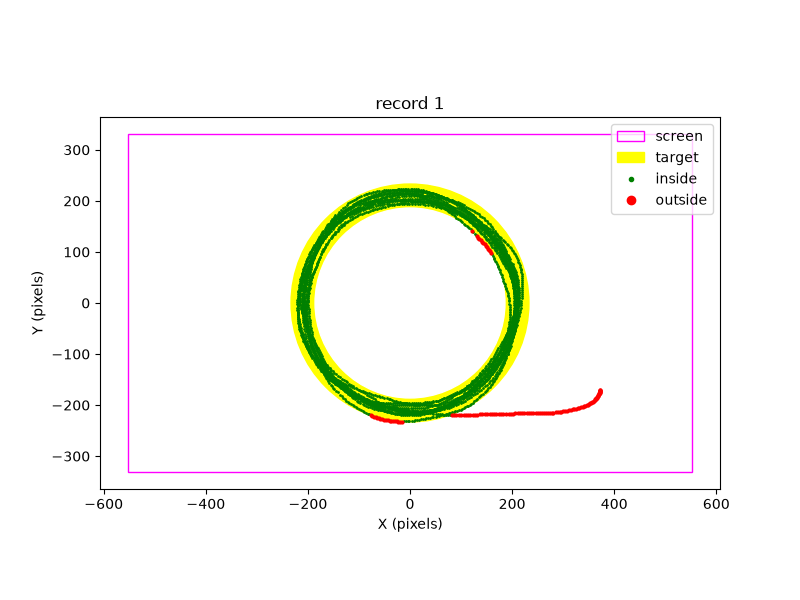

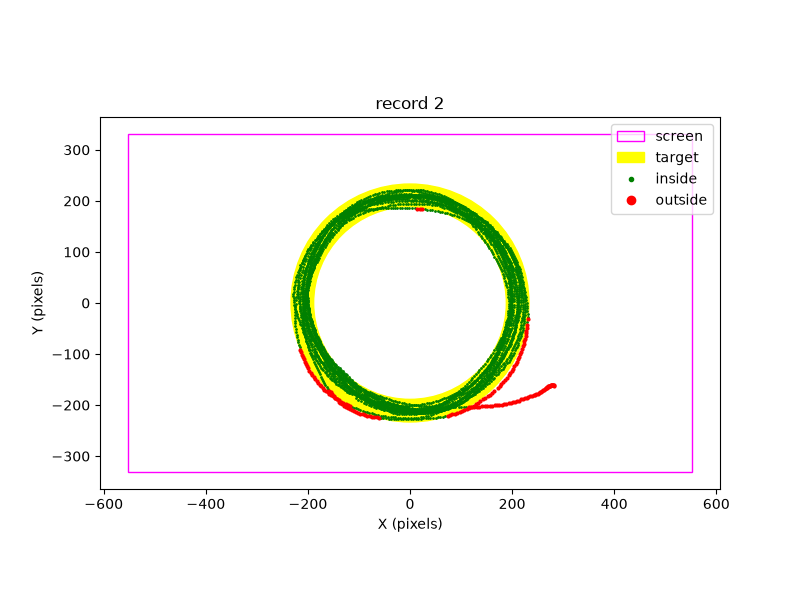

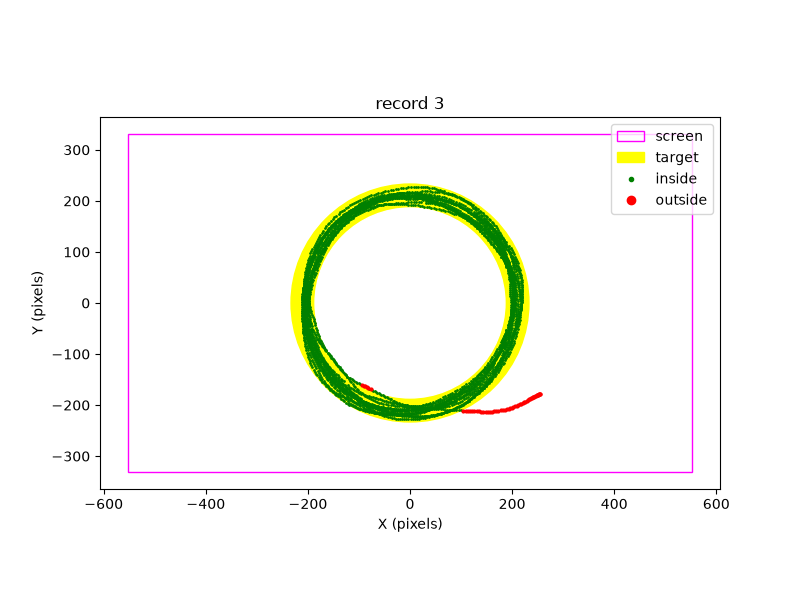

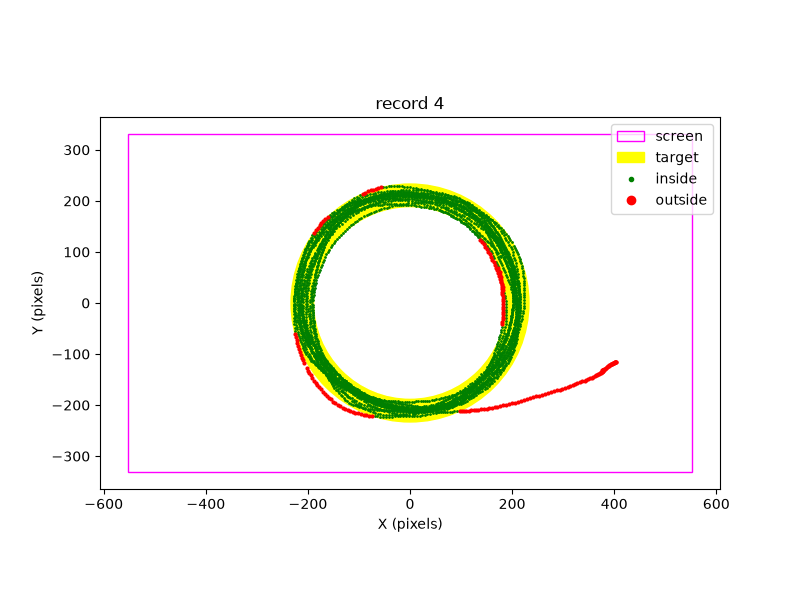

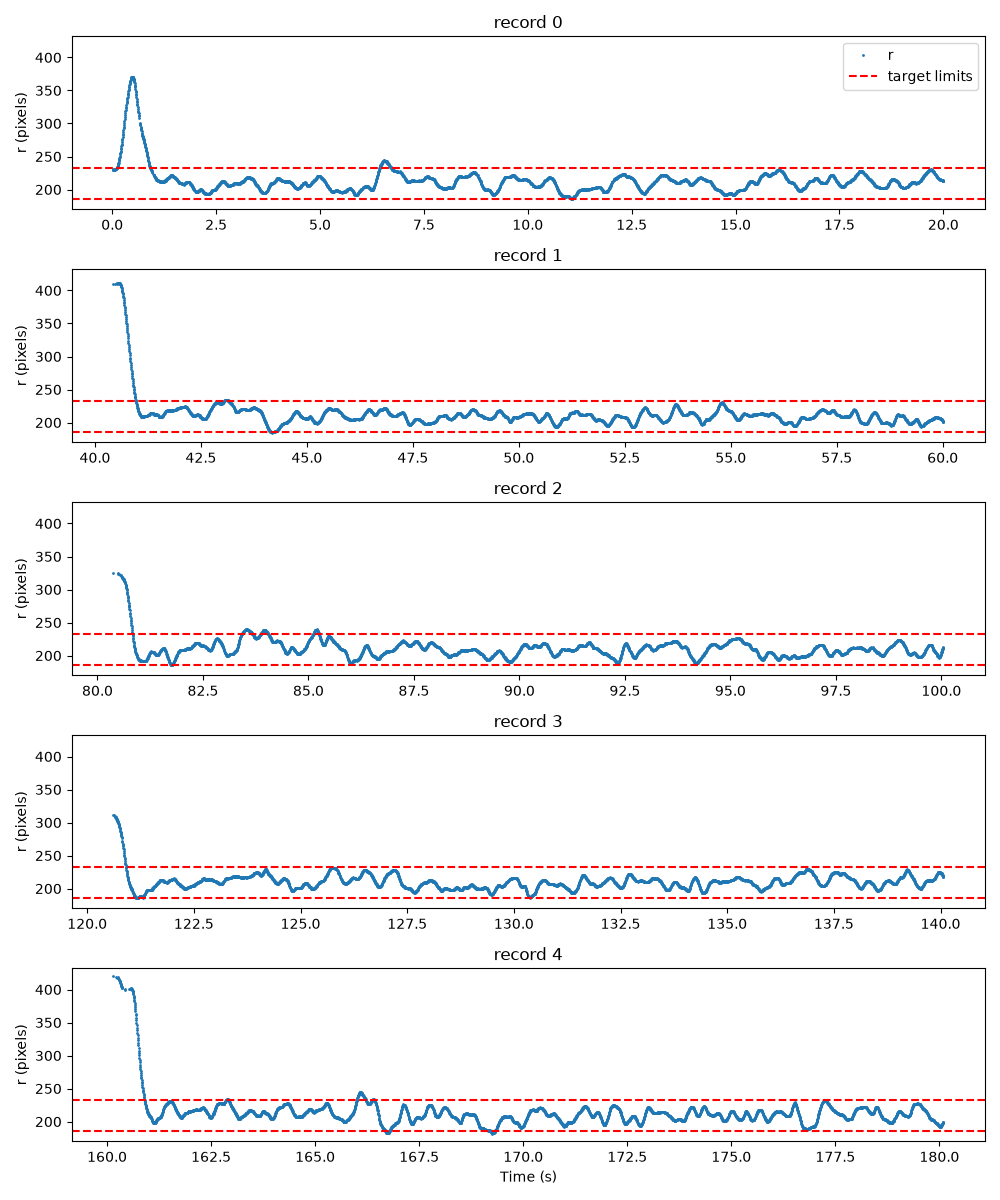

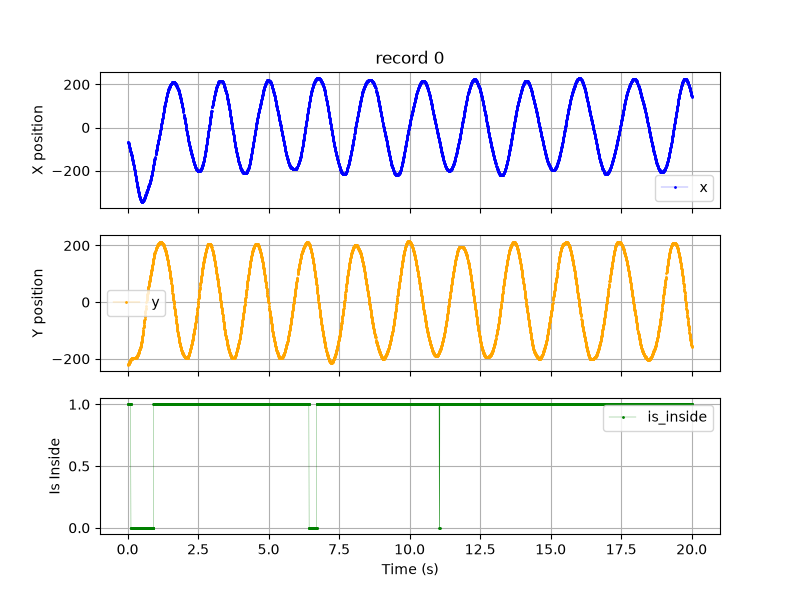

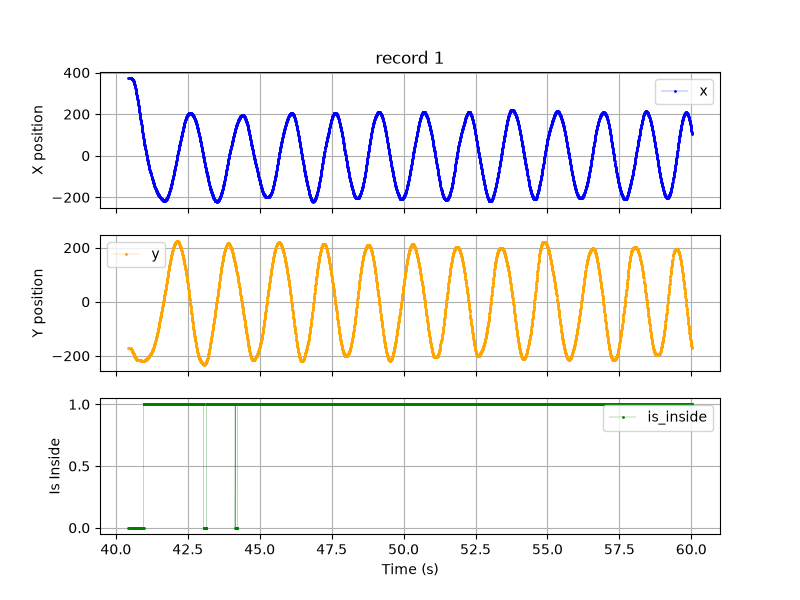

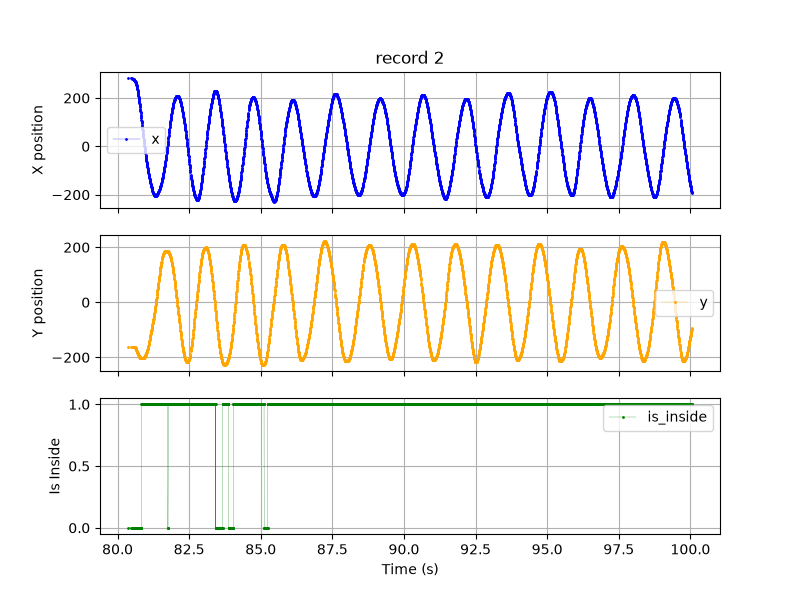

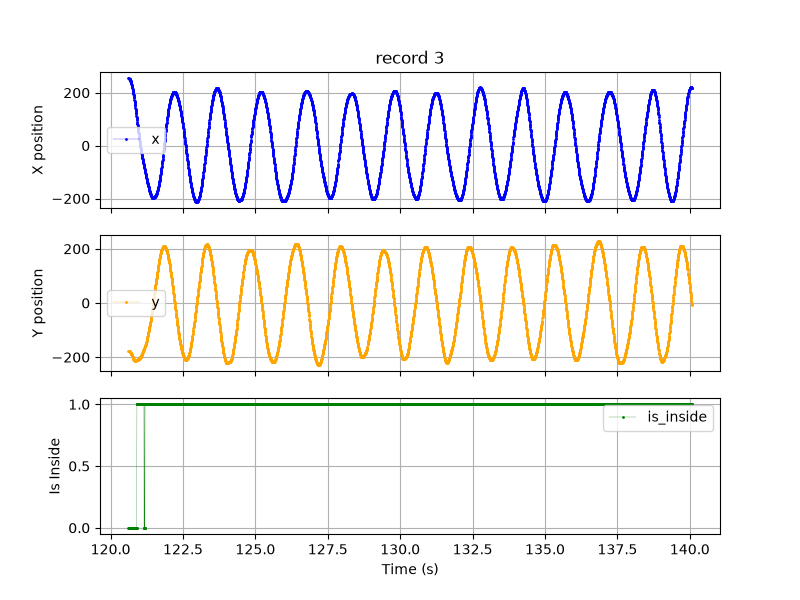

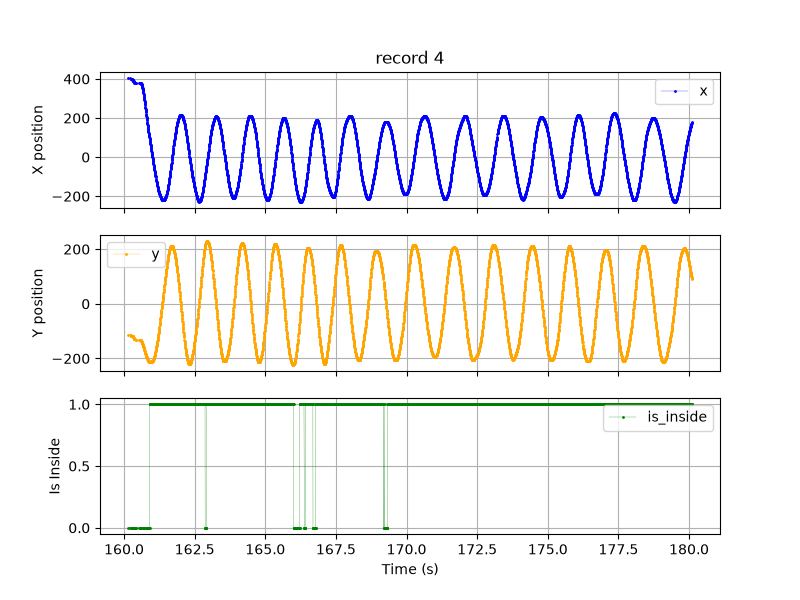

In [2]:
%run notebooks/02_graphics.ipynb

## 3 - Computing (notebooks/03_computing.ipynb)
As in MouseReMoCo, each record is kept from the first entry into the target (92, 58, 52 and 93 samples removed in records 1 to 4).
Then, for each record:
- nLaps = (θ_end - θ_start) / 2π, with θ = angle of the cursor made continuous with np.unwrap.
  nLaps is negative because the cursor turns clockwise (with the y axis pointing up);
- Re = mean of r (effective radius) and Te = 4.133 × SD of r (effective tolerance);
- error = percentage of the angle travelled outside the target;
- MT/lap = duration / |nLaps|, IDe/lap = 2π × Re / Te (steering law), Be = Te / 47 and IPe = IDe/lap / MT/lap.

Main results:
- the number of laps increases overall (from 10.84 to 14.74 laps) and MT/lap decreases (from 1.84 to 1.30 s/lap),
  but not at every record (record 3 is slower than record 2);
- record 0 has a much larger Te (91.79 px, Be = 1.95) because of the loop at its beginning,
  so its IDe/lap and IPe are low (14.64 bit/lap and 7.94 bit/s);
- in records 1 to 4, Be is below 1 (0.73 to 0.93) and IPe is about 21 to 24 bit/s.

A summary table with all the values is printed at the end.

In [3]:
%run notebooks/03_computing.ipynb

record 0: first entry at   0.022 s (sample 0), 3971 samples kept
record 1: first entry at  40.966 s (sample 92), 3806 samples kept
record 2: first entry at  80.832 s (sample 58), 3840 samples kept
record 3: first entry at 120.908 s (sample 52), 3832 samples kept
record 4: first entry at 160.908 s (sample 93), 3843 samples kept
record 0: nLaps = -10.84
record 1: nLaps = -11.97
record 2: nLaps = -13.26
record 3: nLaps = -12.83
record 4: nLaps = -14.74
record 0: Re = 213.86 px Te =  91.79 px error =   3.90 %
record 1: Re = 209.85 px Te =  34.45 px error =   0.74 %
record 2: Re = 209.43 px Te =  42.42 px error =   2.81 %
record 3: Re = 209.46 px Te =  37.14 px error =   0.13 %
record 4: Re = 210.89 px Te =  43.88 px error =   2.84 %
record 0: MT/lap =  1.84 s/lap IDe/lap =  14.64 bit/lap Be =  1.95 IPe =   7.94 bit/s
record 1: MT/lap =  1.59 s/lap IDe/lap =  38.27 bit/lap Be =  0.73 IPe =  24.04 bit/s
record 2: MT/lap =  1.45 s/lap IDe/lap =  31.02 bit/lap Be =  0.90 IPe =  21.40 bit/s
rec

## 4 - Comparison with MouseReMoCo (notebooks/04_comparison.ipynb)
We read the table written by MouseReMoCo at the end of the marker file and compare it to our values.
For each variable, the largest difference between the two tables is printed.
This comparison is automatic, so it also works on our own recordings (task 11).

In [4]:
%run notebooks/04_comparison.ipynb

nLaps   : max difference = 0.01
Re      : max difference = 0.01
Te      : max difference = 0.01
error   : max difference = 0.00
MT/lap  : max difference = 0.00
IDe/lap : max difference = 0.00
Be      : max difference = 0.00
IPe     : max difference = 0.00


## Conclusion
All our values are the same as the MouseReMoCo table, with a difference of at most 0.01, due to rounding
(nLaps of record 0: -10.84 vs -10.85, Re of record 0: 213.86 vs 213.87, Te of record 1: 34.45 vs 34.46).
Our code reproduces the analysis of MouseReMoCo: it reads the files, splits the records, plots the movement
and recomputes all the statistics. It can now be used on our own recordings (task 11).